In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


In [15]:
df =pd.read_csv("wine_data.csv", header=None ,usecols=[0,1,2])
df.columns=['Class_label','Alcohol','Malic acid']
df

,Class_label,Alcohol,Malic acid
0,1,14.23,1.71
1,1,13.20,1.78
2,1,13.16,2.36
3,1,14.37,1.95
4,1,13.24,2.59
...,...,...,...
173,3,13.71,5.65
174,3,13.40,3.91
175,3,13.27,4.28
176,3,13.17,2.59


<Axes: xlabel='Alcohol', ylabel='Density'>

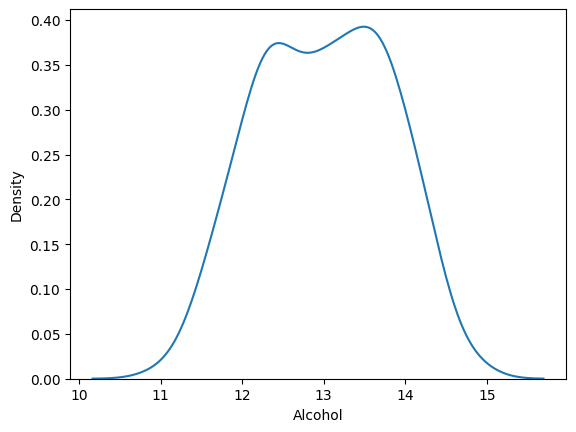

In [16]:
sns.kdeplot(df['Alcohol'])

<Axes: xlabel='Malic acid', ylabel='Density'>

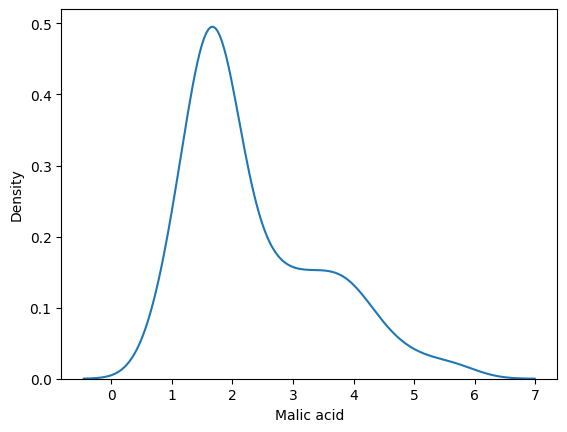

In [17]:
sns.kdeplot(df['Malic acid'])

<Axes: xlabel='Alcohol', ylabel='Malic acid'>

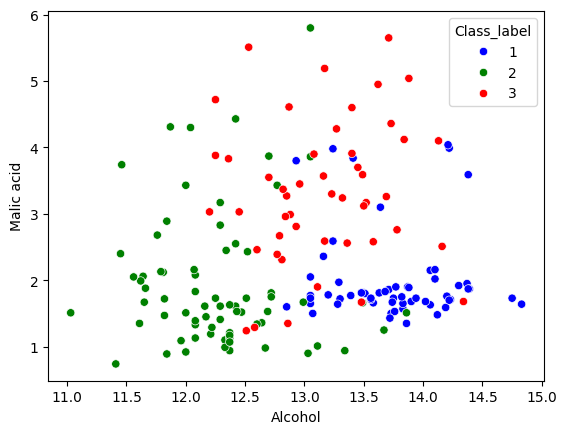

In [24]:
color_dict={1:'blue',2:'green',3:'red'}
sns.scatterplot(x=df['Alcohol'], y=df['Malic acid'], hue=df['Class_label'], palette=color_dict)

In [27]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(df.drop('Class_label',axis=1),
                                               df['Class_label'],
                                               test_size=0.2
                                               ,random_state=0)
x_train.shape,y_train.shape,x_test.shape,y_test.shape


((142, 2), (142,), (36, 2), (36,))

In [28]:
from sklearn.preprocessing import MinMaxScaler
scaler=MinMaxScaler()
x_train_scaler=scaler.fit_transform(x_train)
x_test_scaler=scaler.transform(x_test)

In [29]:
x_train_scaler=pd.DataFrame(x_train_scaler,columns=x_train.columns)
x_test_scaler=pd.DataFrame(x_test_scaler,columns=x_test.columns)

In [30]:
np.round(x_train_scaler.describe(),1)

,Alcohol,Malic acid
count,142.0,142.0
mean,0.5,0.3
std,0.2,0.2
min,0.0,0.0
25%,0.4,0.2
50%,0.5,0.2
75%,0.7,0.5
max,1.0,1.0


In [31]:
np.round(x_train.describe(),1)

,Alcohol,Malic acid
count,142.0,142.0
mean,13.0,2.4
std,0.8,1.1
min,11.0,0.7
25%,12.3,1.6
50%,13.0,1.9
75%,13.6,3.2
max,14.8,5.6


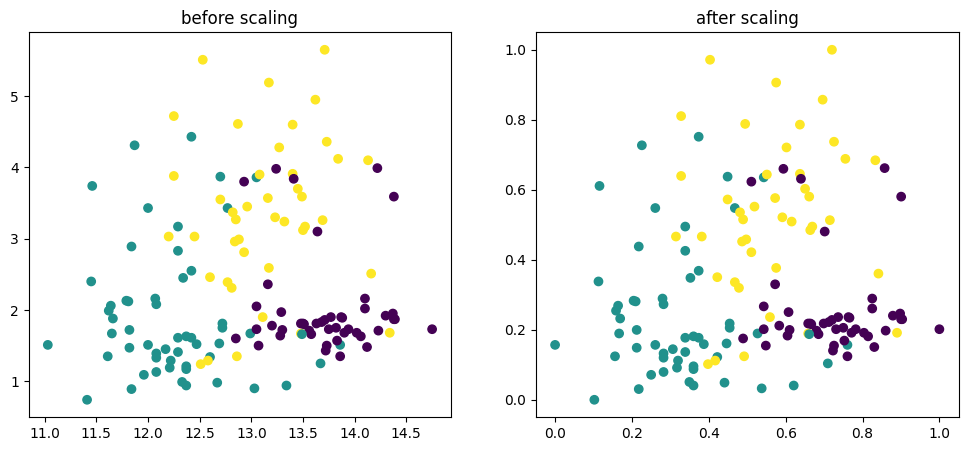

In [34]:
fig,(ax1,ax2)=plt.subplots(ncols=2,figsize=(12,5))

ax1.scatter(x_train['Alcohol'],x_train['Malic acid'],c=y_train)
ax1.set_title('before scaling')

ax2.scatter(x_train_scaler['Alcohol'],x_train_scaler['Malic acid'],c=y_train)
ax2.set_title('after scaling')

plt.show()

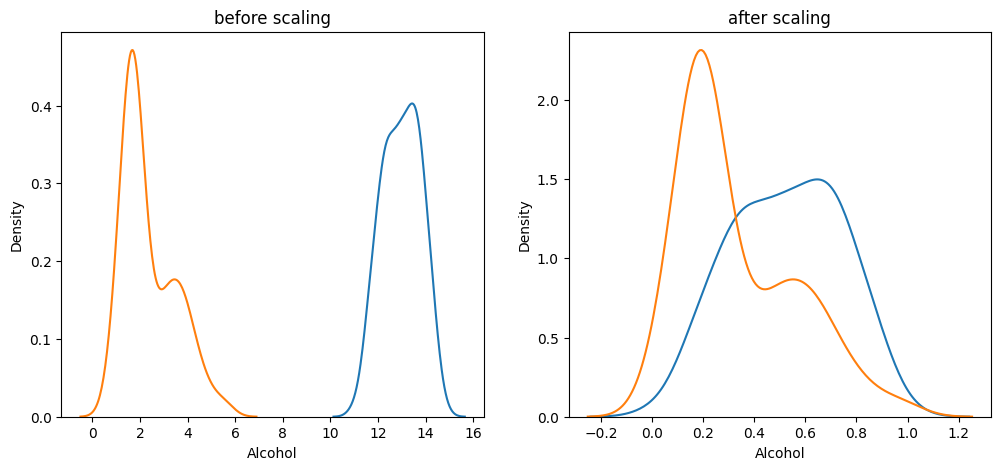

In [35]:
fig,(ax1,ax2)=plt.subplots(ncols=2,figsize=(12,5))

ax1.set_title('before scaling')
sns.kdeplot(x_train['Alcohol'],ax=ax1)
sns.kdeplot(x_train['Malic acid'],ax=ax1)

ax2.set_title('after scaling')
sns.kdeplot(x_train_scaler['Alcohol'],ax=ax2)
sns.kdeplot(x_train_scaler['Malic acid'],ax=ax2)

plt.show()

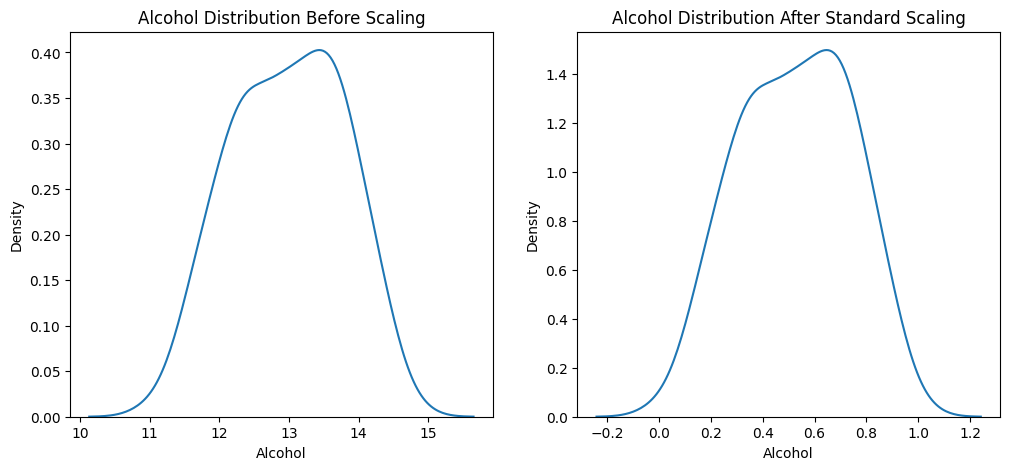

In [37]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))

# before scaling
ax1.set_title('Alcohol Distribution Before Scaling')
sns.kdeplot(x_train['Alcohol'], ax=ax1)

# after scaling
ax2.set_title('Alcohol Distribution After Standard Scaling')
sns.kdeplot(x_train_scaler['Alcohol'], ax=ax2)
plt.show()

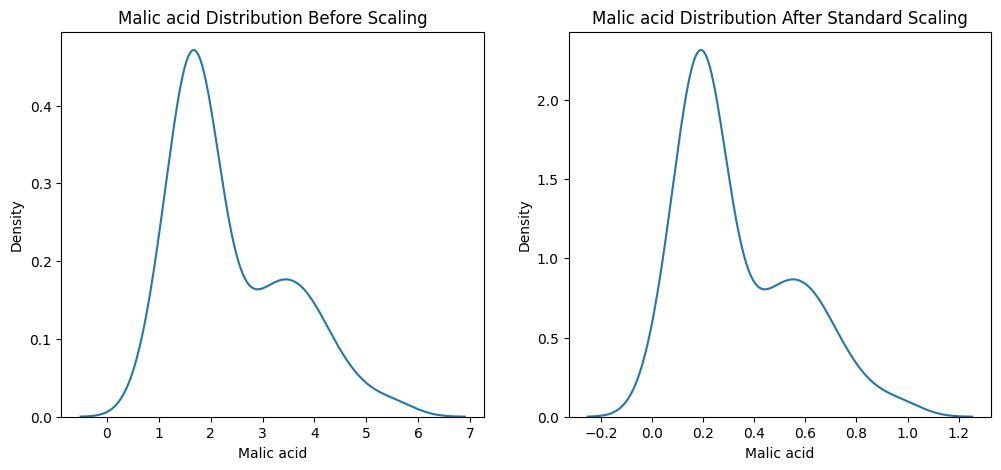

In [39]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))

# before scaling
ax1.set_title('Malic acid Distribution Before Scaling')
sns.kdeplot(x_train['Malic acid'], ax=ax1)

# after scaling
ax2.set_title('Malic acid Distribution After Standard Scaling')
sns.kdeplot(x_train_scaler['Malic acid'], ax=ax2)
plt.show()